In [10]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Direct path from notebooks directory
data_path = os.path.join("..", "data", "squad_2.0_dev_complete_11873.xlsx")

print(f"Loading {data_path} (reading Excel will take a few seconds)...")
df_val = pd.read_excel(data_path)

print(f"\n[+] Successfully loaded!")
print(f"Dataset Shape: {df_val.shape}")
print(f"Columns: {df_val.columns.tolist()}\n")

# Display the first 2 rows
df_val.head(2)

Loading ..\data\squad_2.0_dev_complete_11873.xlsx (reading Excel will take a few seconds)...

[+] Successfully loaded!
Dataset Shape: (11873, 9)
Columns: ['title', 'context', 'question', 'ids', 'answers', 'answer_start', 'plausible_answers', 'plausible_answers_start', 'is_impossible']



,title,context,question,ids,answers,answer_start,plausible_answers,plausible_answers_start,is_impossible
0,Normans,['The Normans (Norman: Nourmands; French: Norm...,In what country is Normandy located?,56ddde6b9a695914005b9628,"['France', 'France', 'France', 'France']","[159, 159, 159, 159]",No answer,--,False
1,Normans,['The Normans (Norman: Nourmands; French: Norm...,When were the Normans in Normandy?,56ddde6b9a695914005b9629,"['10th and 11th centuries', 'in the 10th and 1...","[94, 87, 94, 94]",No answer,--,False


SQuAD 2.0 Class Balance:
  Answerable (False):    5928 (49.93%)
  Unanswerable (True):  5945 (50.07%)

Context Word Count Statistics:
count    11873.000000
mean       127.907858
std         57.298905
min         25.000000
50%        114.000000
90%        191.000000
95%        226.000000
99%        356.000000
max        629.000000
Name: context_word_count, dtype: float64

Question Word Count Statistics:
count    11873.000000
mean        10.019624
std          3.488700
min          3.000000
50%         10.000000
90%         15.000000
95%         16.000000
99%         21.000000
max         31.000000
Name: question_word_count, dtype: float64


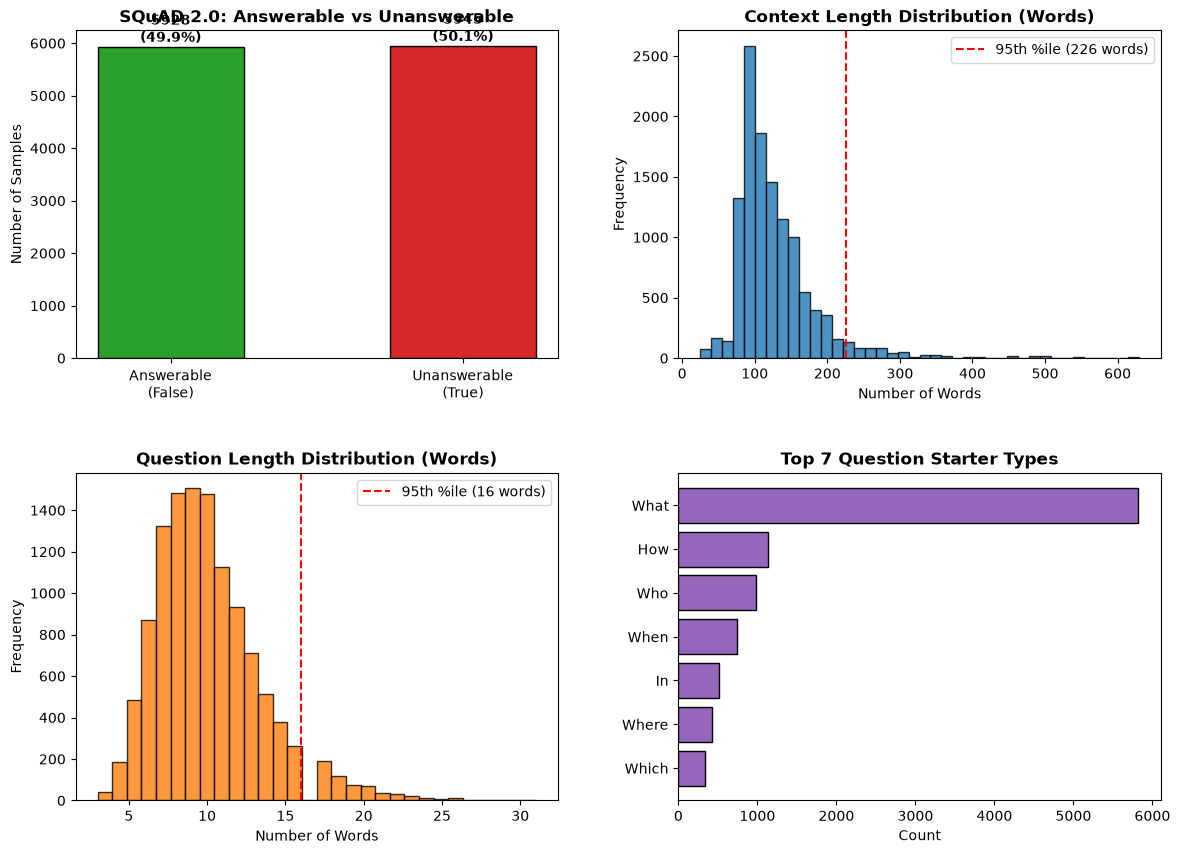

In [11]:
# ==========================================================
# Task 2.2: Statistical Analysis and Visualizations
# ==========================================================

# 1. Class Distribution: Answerable vs Unanswerable
class_counts = df_val['is_impossible'].value_counts()
class_pcts = df_val['is_impossible'].value_counts(normalize=True) * 100

print("=" * 55)
print("SQuAD 2.0 Class Balance:")
print(f"  Answerable (False):   {class_counts[False]:>5} ({class_pcts[False]:.2f}%)")
print(f"  Unanswerable (True): {class_counts[True]:>5} ({class_pcts[True]:.2f}%)")
print("=" * 55)

# 2. Length Analysis (Word Counts)
# Note: context is stored as a string representation of list in some rows, so we clean it
def get_clean_text(val):
    text = str(val)
    if text.startswith("['") and text.endswith("']"):
        return text[2:-2]
    return text

df_val['clean_context'] = df_val['context'].apply(get_clean_text)
df_val['context_word_count'] = df_val['clean_context'].apply(lambda x: len(str(x).split()))
df_val['question_word_count'] = df_val['question'].apply(lambda x: len(str(x).split()))

print("\nContext Word Count Statistics:")
print(df_val['context_word_count'].describe(percentiles=[0.50, 0.90, 0.95, 0.99]))

print("\nQuestion Word Count Statistics:")
print(df_val['question_word_count'].describe(percentiles=[0.50, 0.90, 0.95, 0.99]))

# 3. Linguistic Breakdown: Question Starting Word
df_val['question_type'] = df_val['question'].apply(lambda x: str(x).strip().split()[0].title() if len(str(x).split()) > 0 else "Unknown")
top_q_types = df_val['question_type'].value_counts().head(7)

# 4. Plot 4-Panel EDA Dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# Plot A: Class Balance (Bar Chart)
axes[0, 0].bar(['Answerable\n(False)', 'Unanswerable\n(True)'], 
               [class_counts[False], class_counts[True]], 
               color=['#2ca02c', '#d62728'], edgecolor='black', width=0.5)
axes[0, 0].set_title("SQuAD 2.0: Answerable vs Unanswerable", fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel("Number of Samples")
for i, v in enumerate([class_counts[False], class_counts[True]]):
    axes[0, 0].text(i, v + 100, f"{v}\n({v/len(df_val)*100:.1f}%)", ha='center', fontweight='bold')

# Plot B: Context Length Distribution
axes[0, 1].hist(df_val['context_word_count'], bins=40, color='#1f77b4', edgecolor='black', alpha=0.8)
axes[0, 1].axvline(df_val['context_word_count'].quantile(0.95), color='red', linestyle='--', label=f"95th %ile ({int(df_val['context_word_count'].quantile(0.95))} words)")
axes[0, 1].set_title("Context Length Distribution (Words)", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Number of Words")
axes[0, 1].set_ylabel("Frequency")
axes[0, 1].legend()

# Plot C: Question Length Distribution
axes[1, 0].hist(df_val['question_word_count'], bins=30, color='#ff7f0e', edgecolor='black', alpha=0.8)
axes[1, 0].axvline(df_val['question_word_count'].quantile(0.95), color='red', linestyle='--', label=f"95th %ile ({int(df_val['question_word_count'].quantile(0.95))} words)")
axes[1, 0].set_title("Question Length Distribution (Words)", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Number of Words")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].legend()

# Plot D: Top Question Types
axes[1, 1].barh(top_q_types.index[::-1], top_q_types.values[::-1], color='#9467bd', edgecolor='black')
axes[1, 1].set_title("Top 7 Question Starter Types", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Count")

plt.show()